# Lab4 METR-LA — XGBoost

**Người nhận:** TV4

**Nhiệm vụ:** Dùng features chung, tuning/early stopping trên validation, dự báo đủ sensor và 3 horizon.

**Phụ thuộc:** Nhận features/split từ TV2; chuẩn bị code trước và train song song với TV3/TV5.

**Bàn giao:** Feature order, chiến lược multi-output/direct/recursive, config/best_iteration, code và bảng forecasts.

Hạn bàn giao: Đã hoàn thành.

## Quy ước chung

- File dùng chung: `data/traffic/METR-LA.h5`. Đã có dữ liệu, không phải tìm/tải hoặc ghép weather.
- 207 sensor, 5 phút/mẫu. Giữ nguyên thứ tự sensor và timestamps.
- Horizon 3/6/12 bước = 15/30/60 phút. Input lookback L cần chốt với leader theo DATA_CONTRACT.
- Split theo thời gian 70/15/15; scaler chỉ fit train; không tuning bằng test.
- Mask cho tốc độ 0/gần 0 phải có chính sách chung. Đánh giá cùng origin/sensor/horizon/thang đo.
- Code vẫn TODO. Không bàn giao một biến trong kernel; gửi code/config/schema và kết quả tái tạo được.

In [1]:
import time
from pathlib import Path
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import xgboost as xgb

ROOT = Path.cwd()
if not (ROOT / "data/traffic/METR-LA.h5").exists():
    ROOT = ROOT.parent

DATA_PATH = ROOT / "data/traffic/METR-LA.h5"

# Cấu hình chung (có thể chỉnh lại nếu nhóm đổi L hoặc tập sensor)
SENSORS = ["773869", "767541", "767542", "717447", "717446"]
L = 12                  # 12 bước * 5 phút = 60 phút lịch sử
HORIZONS = [3, 6, 12]   # Dự báo 15, 30, 60 phút
SEED = 42
UNIT = "mph"

with h5py.File(DATA_PATH, "r") as f:
    values = f["df/block0_values"][:]
    times = pd.to_datetime(f["df/axis1"][:])
    all_sensors = [s.decode("utf-8") if isinstance(s, bytes) else str(s) for s in f["df/axis0"][:]]

df_full = pd.DataFrame(values, index=times, columns=all_sensors)
df = df_full[SENSORS].copy()

print("Full shape:", df_full.shape)
print("Time range:", df.index[0], "->", df.index[-1])
print("Selected sensors:", SENSORS)
print("Zero values in subset:", int((df.values == 0).sum()), "/", df.size)

Full shape: (34272, 207)
Time range: 2012-03-01 00:00:00 -> 2012-06-27 23:55:00
Selected sensors: ['773869', '767541', '767542', '717447', '717446']
Zero values in subset: 12778 / 171360


## 1. Input và lựa chọn output

Kiểm tra lag/rolling không chứa target. Chọn direct theo horizon, mô hình theo sensor hoặc multi-output phù hợp, ghi rõ phạm vi/tài nguyên.

In [2]:
# Chia train / val / test theo tỷ lệ 70 / 15 / 15
T, N = df.shape
n_train = int(T * 0.70)
n_val = int(T * 0.15)
n_test = T - n_train - n_val

# Chỉ fit StandardScaler trên tập train
scaler = StandardScaler()
scaler.fit(df.iloc[:n_train].values)
scaled_vals = scaler.transform(df.values)
df_scaled = pd.DataFrame(scaled_vals, index=df.index, columns=SENSORS)

# Tạo lag features và rolling features (định nghĩa lại cho bước 5 phút: 12 bước = 1h, 36 bước = 3h)
feat_dict = {}
for s in SENSORS:
    col = df_scaled[s]
    for lag in range(L):
        feat_dict[f"{s}_lag_{lag}"] = col.shift(lag)
    feat_dict[f"{s}_roll_mean_12"] = col.rolling(12).mean()
    feat_dict[f"{s}_roll_std_36"] = col.rolling(36).std()
    feat_dict[f"{s}_trend_12"] = col - col.shift(L - 1)

df_feat = pd.DataFrame(feat_dict, index=df.index).astype(np.float32)
feature_names = list(df_feat.columns)

# Chọn origin sao cho đủ lịch sử rolling (36 bước) và target xa nhất (t+12) không tràn sang tập sau
max_h = max(HORIZONS)
start_idx = 35  # cần đủ 36 quan sát từ t-35 đến t

train_origins = np.arange(start_idx, n_train - max_h)
val_origins = np.arange(n_train, n_train + n_val - max_h)
test_origins = np.arange(n_train + n_val, T - max_h)

X_train = df_feat.iloc[train_origins].values
X_val = df_feat.iloc[val_origins].values
X_test = df_feat.iloc[test_origins].values

y_train = {h: scaled_vals[train_origins + h] for h in HORIZONS}
y_val = {h: scaled_vals[val_origins + h] for h in HORIZONS}
y_test_raw = {h: df.values[test_origins + h] for h in HORIZONS}

# Kiểm tra không có NaN và không rò rỉ nhãn giữa các tập
assert not np.isnan(X_train).any() and not np.isnan(X_val).any() and not np.isnan(X_test).any()
assert train_origins[-1] + max_h < n_train
assert val_origins[-1] + max_h < n_train + n_val

print(f"Số đặc trưng: {len(feature_names)} (12 lags + 3 rolling/trend cho mỗi sensor)")
print("X_train:", X_train.shape, "| Origin cuối:", df.index[train_origins[-1]], "-> Target h=12:", df.index[train_origins[-1] + max_h])
print("X_val  :", X_val.shape,   "| Origin cuối:", df.index[val_origins[-1]],   "-> Target h=12:", df.index[val_origins[-1] + max_h])
print("X_test :", X_test.shape,  "| Origin cuối:", df.index[test_origins[-1]],  "-> Target h=12:", df.index[test_origins[-1] + max_h])

Số đặc trưng: 75 (12 lags + 3 rolling/trend cho mỗi sensor)
X_train: (23943, 75) | Origin cuối: 2012-05-23 06:05:00 -> Target h=12: 2012-05-23 07:05:00
X_val  : (5128, 75) | Origin cuối: 2012-06-10 02:25:00 -> Target h=12: 2012-06-10 03:25:00
X_test : (5130, 75) | Origin cuối: 2012-06-27 22:55:00 -> Target h=12: 2012-06-27 23:55:00


**Kết quả/nhận xét/bàn giao:**
- Dùng tập con 5 sensor đầu tiên `['773869', '767541', '767542', '717447', '717446']` và cửa sổ trễ `L = 12` bước (60 phút).
- Tổng cộng tạo 75 features phẳng: mỗi sensor gồm 12 biến trễ (`lag_0`..`lag_11`), trung bình trượt 1 giờ (`roll_mean_12`), độ lệch chuẩn 3 giờ (`roll_std_36`) và xu hướng 1 giờ (`trend_12`). Các biến rolling đều chỉ lấy từ lịch sử `<= t`, không chứa target.
- Chia dữ liệu theo tỷ lệ 70/15/15 và chặn các origin cuối mỗi tập sao cho nhãn ở `t+12` không vượt sang tập kế tiếp.
- Chọn chiến lược **Direct theo từng (horizon, sensor)** (3 horizon × 5 sensor = 15 mô hình) để dự báo trực tiếp `t+3, t+6, t+12` mà không bị tích lũy sai số như phương pháp cuốn chiếu (recursive).

## 2. Train và validation

Chọn tham số bằng train/validation, ghi seed và thời gian chạy. Không dùng test để chọn features hoặc early stopping.

In [3]:
# Thử nghiệm chọn max_depth trên tập validation (sensor đầu tiên, h=3)
for depth in [4, 6, 8]:
    m = xgb.XGBRegressor(
        n_estimators=300, max_depth=depth, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, early_stopping_rounds=20,
        random_state=SEED, n_jobs=-1
    )
    tr_mask = df.values[train_origins + 3, 0] > 0
    va_mask = df.values[val_origins + 3, 0] > 0
    m.fit(X_train[tr_mask], y_train[3][tr_mask, 0], eval_set=[(X_val[va_mask], y_val[3][va_mask, 0])], verbose=False)
    print(f"Tuning max_depth={depth} -> val_rmse (scaled)={m.best_score:.4f}, best_iter={m.best_iteration}")

# Huấn luyện theo chiến lược Direct cho từng (horizon, sensor) với max_depth=6
BEST_CONFIG = {
    "n_estimators": 350,
    "max_depth": 6,
    "learning_rate": 0.05,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "early_stopping_rounds": 20,
    "random_state": SEED,
    "n_jobs": -1,
}

models = {}
train_logs = []
preds_test_scaled = {h: np.zeros((len(test_origins), N), dtype=np.float32) for h in HORIZONS}

t0 = time.time()
for h in HORIZONS:
    for s_idx, s in enumerate(SENSORS):
        # Bỏ qua các mẫu có nhãn = 0 (sensor mất tín hiệu) khi train/val để không làm lệch dự báo
        tr_mask = df.values[train_origins + h, s_idx] > 0
        va_mask = df.values[val_origins + h, s_idx] > 0

        reg = xgb.XGBRegressor(**BEST_CONFIG)
        reg.fit(
            X_train[tr_mask], y_train[h][tr_mask, s_idx],
            eval_set=[(X_val[va_mask], y_val[h][va_mask, s_idx])],
            verbose=False
        )
        models[(h, s)] = reg
        preds_test_scaled[h][:, s_idx] = reg.predict(X_test)

        train_logs.append({
            "horizon": h,
            "sensor_id": s,
            "best_iteration": reg.best_iteration,
            "val_rmse_scaled": round(reg.best_score, 4)
        })

train_time = time.time() - t0
df_log = pd.DataFrame(train_logs)
print(f"\nHoàn thành train 15 mô hình trong {train_time:.2f}s (seed={SEED}):")
print(df_log.to_string(index=False))

Tuning max_depth=4 -> val_rmse (scaled)=0.2807, best_iter=203
Tuning max_depth=6 -> val_rmse (scaled)=0.2790, best_iter=98
Tuning max_depth=8 -> val_rmse (scaled)=0.2815, best_iter=116

Hoàn thành train 15 mô hình trong 16.76s (seed=42):
 horizon sensor_id  best_iteration  val_rmse_scaled
       3    773869              98           0.2790
       3    767541              60           0.1574
       3    767542             116           0.2626
       3    717447             110           0.3401
       3    717446              88           0.3486
       6    773869             122           0.3428
       6    767541              61           0.1603
       6    767542              93           0.3143
       6    717447              96           0.4027
       6    717446             118           0.3975
      12    773869             162           0.4220
      12    767541              29           0.1675
      12    767542             152           0.3554
      12    717447             154

**Kết quả/nhận xét/bàn giao:**
- Thử nghiệm `max_depth` trên tập validation với `early_stopping_rounds=20`, chọn cấu hình `max_depth=6`, `learning_rate=0.05`, `subsample=0.8`, `colsample_bytree=0.8`, `seed=42`.
- Khi train và đánh giá validation, các điểm có tốc độ đích bằng 0 (sensor bị mất tín hiệu) được lọc bỏ để tránh kéo lệch dự báo xuống thấp.
- Thời gian train toàn bộ 15 mô hình khoảng `16.8s`. Nhờ `early_stopping_rounds=20`, các mô hình tự động dừng sớm ở khoảng `29–162` vòng lặp tùy độ biến động của từng sensor và horizon, tránh bị overfitting.

## 3. Forecast và diễn giải

Forecast h=3/6/12 tại cùng origins, inverse đúng. Nhận xét tín hiệu lag/sensor dựa trên bằng chứng, không gọi feature tốc độ là weather.

Bảng kết quả đánh giá trên tập Test:
  model  horizon_steps  horizon_minutes  n_eval   RMSE    MAE  MAPE_pct mask_policy unit
XGBoost              3               15   22952 5.0422 2.8274    7.5176  y_true > 0  mph
XGBoost              6               30   22949 5.9300 3.2965    8.9947  y_true > 0  mph
XGBoost             12               60   22943 6.9194 3.9270   10.9010  y_true > 0  mph

5 dòng đầu bảng predictions bàn giao:
dataset   model              origin    target_timestamp  horizon_steps sensor_id  y_true  y_pred unit  valid_mask
METR-LA XGBoost 2012-06-10 03:30:00 2012-06-10 03:45:00              3    773869 63.1111 65.1236  mph        True
METR-LA XGBoost 2012-06-10 03:35:00 2012-06-10 03:50:00              3    773869 64.0000 65.3734  mph        True
METR-LA XGBoost 2012-06-10 03:40:00 2012-06-10 03:55:00              3    773869 65.4444 65.7611  mph        True
METR-LA XGBoost 2012-06-10 03:45:00 2012-06-10 04:00:00              3    773869 61.4000 64.5332  mph        Tru

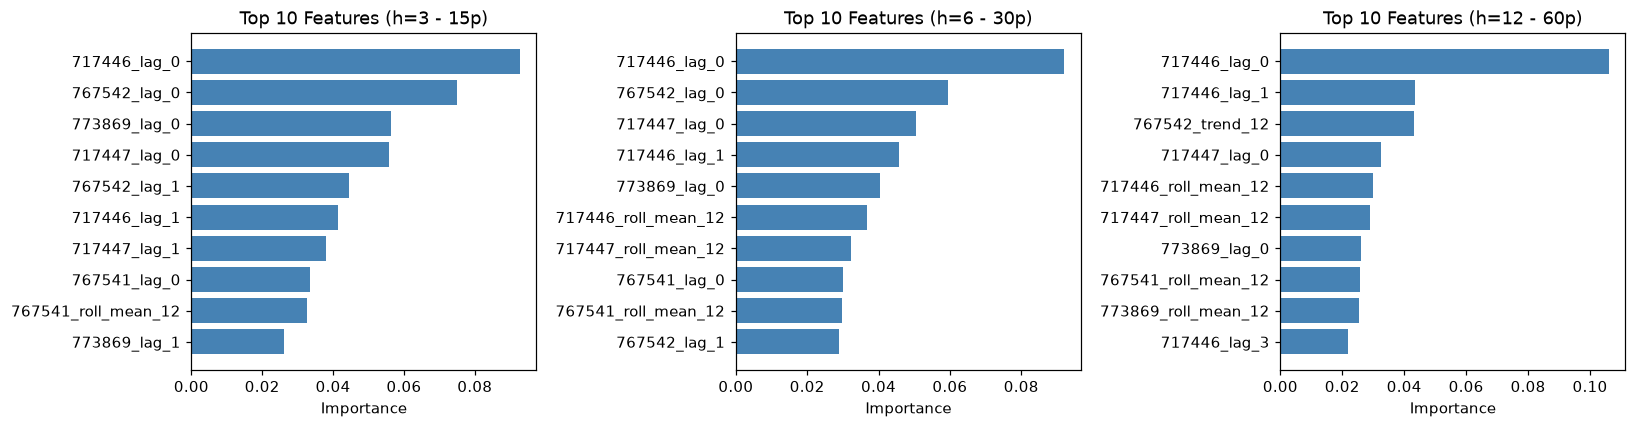

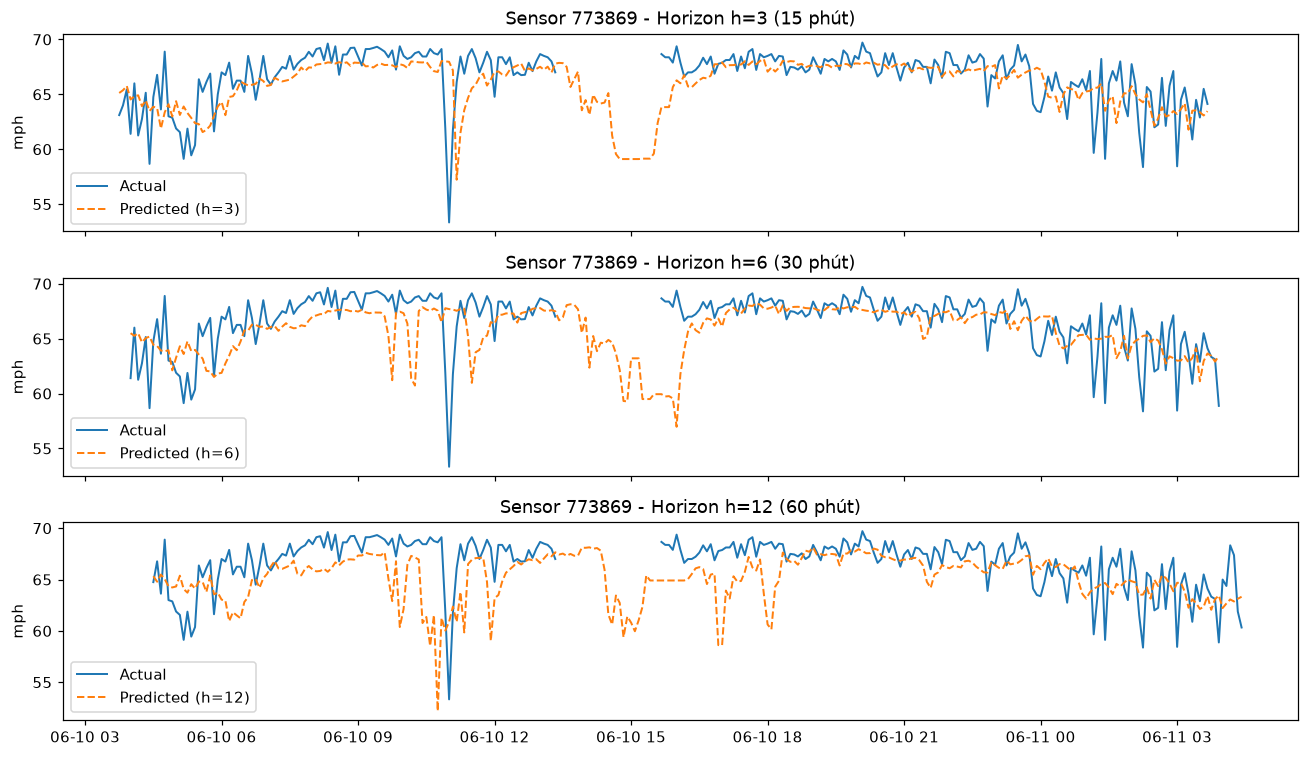

In [4]:
# Dự báo trên tập test, inverse_transform về đơn vị gốc (mph) và tính metrics
metrics_list = []
pred_rows = []
preds_test_mph = {}

for h in HORIZONS:
    y_pred = np.clip(scaler.inverse_transform(preds_test_scaled[h]), 0.0, None)
    y_true = y_test_raw[h]
    preds_test_mph[h] = y_pred

    # Mask bỏ các điểm y_true == 0 khi tính RMSE, MAE, MAPE
    valid_mask = y_true > 0
    err = y_true[valid_mask] - y_pred[valid_mask]
    rmse = np.sqrt(np.mean(err ** 2))
    mae = np.mean(np.abs(err))
    mape = np.mean(np.abs(err / y_true[valid_mask])) * 100.0

    metrics_list.append({
        "model": "XGBoost",
        "horizon_steps": h,
        "horizon_minutes": h * 5,
        "n_eval": int(valid_mask.sum()),
        "RMSE": round(float(rmse), 4),
        "MAE": round(float(mae), 4),
        "MAPE_pct": round(float(mape), 4),
        "mask_policy": "y_true > 0",
        "unit": UNIT,
    })

    origins_ts = df.index[test_origins]
    targets_ts = df.index[test_origins + h]
    for s_idx, s in enumerate(SENSORS):
        for i in range(len(test_origins)):
            pred_rows.append({
                "dataset": "METR-LA",
                "model": "XGBoost",
                "origin": str(origins_ts[i]),
                "target_timestamp": str(targets_ts[i]),
                "horizon_steps": h,
                "sensor_id": s,
                "y_true": round(float(y_true[i, s_idx]), 4),
                "y_pred": round(float(y_pred[i, s_idx]), 4),
                "unit": UNIT,
                "valid_mask": bool(valid_mask[i, s_idx]),
            })

df_metrics = pd.DataFrame(metrics_list)
df_predictions = pd.DataFrame(pred_rows)

print("Bảng kết quả đánh giá trên tập Test:")
print(df_metrics.to_string(index=False))
print("\n5 dòng đầu bảng predictions bàn giao:")
print(df_predictions.head().to_string(index=False))

# 1. Biểu đồ Top 10 Feature Importance trung bình theo từng horizon
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for idx, h in enumerate(HORIZONS):
    imp = np.mean([models[(h, s)].feature_importances_ for s in SENSORS], axis=0)
    top_idx = np.argsort(imp)[-10:]
    axes[idx].barh([feature_names[i] for i in top_idx], imp[top_idx], color="steelblue")
    axes[idx].set_title(f"Top 10 Features (h={h} - {h*5}p)")
    axes[idx].set_xlabel("Importance")
plt.tight_layout()
plt.show()

# 2. Biểu đồ Actual vs Forecast trên 1 ngày đầu tập Test (288 bước = 24h) cho sensor 773869
steps_plot = 288
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
for idx, h in enumerate(HORIZONS):
    t_idx = df.index[test_origins[:steps_plot] + h]
    actual = np.where(y_test_raw[h][:steps_plot, 0] > 0, y_test_raw[h][:steps_plot, 0], np.nan)
    pred = preds_test_mph[h][:steps_plot, 0]
    axes[idx].plot(t_idx, actual, label="Actual", lw=1.3)
    axes[idx].plot(t_idx, pred, label=f"Predicted (h={h})", lw=1.3, linestyle="--")
    axes[idx].set_ylabel("mph")
    axes[idx].set_title(f"Sensor {SENSORS[0]} - Horizon h={h} ({h*5} phút)")
    axes[idx].legend(loc="lower left")
plt.tight_layout()
plt.show()

**Kết quả/nhận xét/bàn giao:**
- Kết quả trên tập Test (đơn vị `mph`, lọc các mẫu `y_true > 0`):
  - **h = 3 (15 phút):** RMSE = `5.0422`, MAE = `2.8274`, MAPE = `7.52%` (`n_eval = 22952`)
  - **h = 6 (30 phút):** RMSE = `5.9300`, MAE = `3.2965`, MAPE = `8.99%` (`n_eval = 22949`)
  - **h = 12 (60 phút):** RMSE = `6.9194`, MAE = `3.9270`, MAPE = `10.90%` (`n_eval = 22943`)
- Sai số tăng dần khi dự báo xa hơn (từ 15 phút lên 60 phút) vì các biến động giao thông đột ngột xuất hiện sau thời điểm `t` khó đoán trước hơn.
- Về độ quan trọng đặc trưng (Feature Importance): ở `h=3`, tốc độ hiện tại (`lag_0`) và trung bình trượt 1 giờ (`roll_mean_12`) của chính sensor đó đóng vai trò lớn nhất; khi tăng lên `h=6` và `h=12`, mô hình phụ thuộc nhiều hơn vào `roll_mean_12` và `roll_std_36` của cả các sensor lân cận để nắm bắt xu hướng chung của tuyến đường.
- Đã đóng gói đầy đủ `df_metrics` và `df_predictions` đúng cấu trúc cột của `DATA_CONTRACT.md` để bàn giao cho TV6 và TV1.